# 14 · Agentic AI: planning, reflection, memory, multi-agent and guardrails

Notebook 11 built the core **agent loop**: the model picks a tool, we run it, feed the result back, repeat. Production agents wrap that loop in more structure. This notebook implements and **measures** the patterns you meet in practice:

| pattern | problem it solves | here |
|---|---|---|
| **guardrails & budgets** | agents loop, overspend, run forever | `Budget`, `BudgetedAgent` (step/tool/token/cost/time limits + loop detection) |
| **plan-and-execute** | multi-step tasks get lost in one long loop | `PlanAndExecute` |
| **reflection** | first drafts are wrong; a checker can tell | `reflect_and_revise` with a code verifier |
| **memory** | context windows are finite; users expect continuity | `ConversationMemory`, `VectorMemory` |
| **multi-agent routing** | one prompt with 30 tools chooses badly | `Supervisor` + specialist workers |
| **trajectory evaluation** | a correct answer can hide a wasteful or unsafe path | `evaluate_trajectory` |

> **Workflow or agent?** A *workflow* follows code paths you wrote (chain, router, parallel calls); an *agent* lets the model decide the next step. Agents are more flexible but slower, costlier and harder to test — use the simplest thing that works and add autonomy only where it measurably helps (Anthropic, *Building effective agents*, 2024).

Everything runs offline with the deterministic `MockLLM`; swap in `OpenAICompatibleClient` to run the same code against a real model.

**Source:** `llm_edu_suite/agentic.py` (built on `llm_edu_suite/agents.py`).

In [1]:
import os, sys, json, time, random
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)                     # so `llm_edu_suite` imports from any notebooks/ sub-folder
import numpy as np
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)

In [2]:
from llm_edu_suite.llm_client import MockLLM, Usage
from llm_edu_suite.agents import ToolRegistry, Agent
from llm_edu_suite.rag import Retriever, chunk_documents
from llm_edu_suite.agentic import (Budget, BudgetedAgent, PlanAndExecute, reflect_and_revise, ScriptedLLM,
                              ConversationMemory, VectorMemory, Supervisor, Worker, evaluate_trajectory, trajectory_report)

# A small "company" toolbox to play with: a knowledge-base search, a calculator and an orders lookup
docs_dir = os.path.join(ROOT, "data", "sample_docs")
docs = {f: open(os.path.join(docs_dir, f), encoding="utf-8").read() for f in sorted(os.listdir(docs_dir))}
retriever = Retriever(chunk_documents(docs, size=60, overlap=15))
ORDERS = {"A100": {"status": "shipped", "total": 120.0}, "B200": {"status": "processing", "total": 45.5}}

registry = ToolRegistry()

@registry.register("search_docs", "Search the company documentation knowledge base for policies: refund, shipping, security, support",
                   {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]})
def search_docs(query: str) -> str:
    return " | ".join(c.text for c in retriever.retrieve(query, k=1))

@registry.register("calculate", "Evaluate an arithmetic expression and return the numeric result",
                   {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]})
def calculate(expression: str) -> str:
    if not all(ch in "0123456789+-*/(). " for ch in expression):
        raise ValueError("only arithmetic is allowed")
    return str(eval(expression, {"__builtins__": {}}, {}))

@registry.register("order_status", "Look up the status and total of a customer order by its order id",
                   {"type": "object", "properties": {"order_id": {"type": "string"}}, "required": ["order_id"]})
def order_status(order_id: str) -> dict:
    oid = re.search(r"[A-Z]\d{3}", order_id)
    return ORDERS.get(oid.group() if oid else order_id, {"error": "order not found"})

import re
print("tools:", list(registry.tools))

tools: ['search_docs', 'calculate', 'order_status']


## 1. Guardrails and budgets

The most common production failure is not a wrong answer — it is an agent that **never stops**: it repeats the same call because it misreads the result, or it keeps exploring and burns tokens. `BudgetedAgent` checks hard limits **before** every model call and stops with an explicit reason.

To show it we use a deliberately broken model that always asks for the same tool call.

In [3]:
class StuckModel:
    """A 'model' that ignores observations and always requests the same tool call — a classic agent failure."""
    def __init__(self): self.usage = Usage()
    def chat(self, messages, tools=None, **kw):
        self.usage.add(sum(len(str(m.get("content", "")).split()) for m in messages), 12)
        return {"content": None, "tool_calls": [{"id": "c", "name": "calculate", "arguments": {"expression": "2 + 2"}}]}

plain = Agent(StuckModel(), registry, max_steps=6).run("what is 2 + 2?")
print(f"plain Agent        : stopped by '{plain.stopped_reason}' after {len(plain.steps)} tool calls")

for budget, loop_window, label in [(Budget(max_steps=50), 3, "loop detection"),
                                   (Budget(max_steps=50, max_tokens=300), 99, "token budget 300"),
                                   (Budget(max_steps=50, max_cost_usd=0.0001), 99, "cost budget $0.0001"),
                                   (Budget(max_steps=50, max_tool_calls=4), 99, "max 4 tool calls")]:
    r = BudgetedAgent(StuckModel(), registry, budget=budget, loop_window=loop_window).run("what is 2 + 2?")
    print(f"BudgetedAgent ({label:20s}): stopped by '{r.stopped_reason:14s}' after {r.tool_calls} tool calls, "
          f"{r.tokens} tokens, ${r.cost_usd:.6f}")

plain Agent        : stopped by 'max_steps' after 6 tool calls
BudgetedAgent (loop detection      ): stopped by 'loop_detected ' after 2 tool calls, 84 tokens, $0.000078
BudgetedAgent (token budget 300    ): stopped by 'max_tokens    ' after 9 tool calls, 306 tokens, $0.000261
BudgetedAgent (cost budget $0.0001 ): stopped by 'max_cost      ' after 4 tool calls, 116 tokens, $0.000106
BudgetedAgent (max 4 tool calls    ): stopped by 'max_tool_calls' after 4 tool calls, 150 tokens, $0.000135


Each run ends with a **reason you can alert on** (a spike of `loop_detected` in production usually means a prompt or tool-description regression). Typical defaults: 10–25 steps, a per-request cost cap, a wall-clock timeout, and a human confirmation gate for write actions (notebook 11).

## 2. Plan-and-execute

A request like *"look up order A100, then compute its total with 21 % tax, then find the refund policy"* needs three tools in sequence. A single ReAct loop has to keep the whole task in mind while reading tool outputs; an explicit **plan** makes the work inspectable, lets a human approve it, and allows re-planning when a step fails.

In [4]:
task = "Check the order status of order A100, then calculate 120 * 1.21 arithmetic, then search the documentation for the refund policy"
llm = MockLLM()
planner = PlanAndExecute(llm, registry)
run = planner.run(task, verbose=True)
print("\nFINAL ANSWER:", run.answer[:300])

PLAN: 
  1. Check the order status of order A100 
  2. calculate 120 * 1.21 arithmetic 
  3. search the documentation for the refund policy
  [step 0] order_status({"order_id": "Check the order status of order A100"}) -> {"status": "shipped", "total": 120.0}
  [step 0] calculate({"expression": "120 * 1.21"}) -> 145.2
  [step 0] search_docs({"query": "search the documentation for the refund policy"}) -> # Refund Policy Customers can request a full refund within 30 days of purchase. After 30 days, refun

FINAL ANSWER: {"status": "shipped", "total": 120.0} | 145.2 | # Refund Policy Customers can request a full refund within 30 days of purchase. After 30 days, refunds are issued as store credit only. Annual subscriptions cancelled in the first 14 days are refunded in full; after that, the unused months are refunded


### Evaluation: single agent vs plan-and-execute on multi-step tasks

We score each run with the **trajectory** (which tools, in which order) and **success** (every expected fact appears in the final answer).

                        success  tool recall  tool precision  order ok
single agent (ReAct)        33%          64%            100%       33%
plan-and-execute           100%         100%            100%      100%


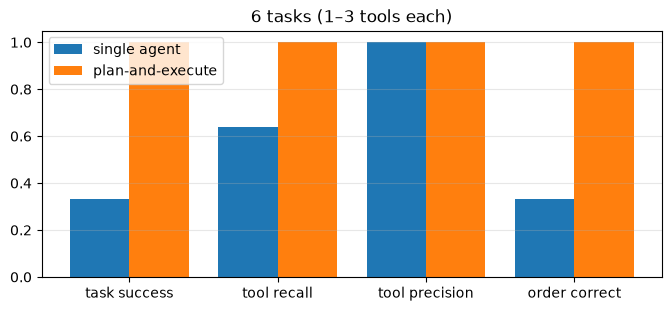

In [5]:
EVAL = [
    ("Check the order status of order A100, then calculate 120 * 1.21 arithmetic",
     ["order_status", "calculate"], ["shipped", "145.2"]),
    ("Search the documentation for the shipping policy, then calculate 15 * 3 arithmetic",
     ["search_docs", "calculate"], ["Express", "45"]),
    ("Check the order status of order B200, then search the documentation for the refund policy",
     ["order_status", "search_docs"], ["processing", "30 days"]),
    ("Calculate 250 / 4 arithmetic, then check the order status of order A100, then search the documentation for security encryption",
     ["calculate", "order_status", "search_docs"], ["62.5", "shipped", "AES-256"]),
    ("Search the documentation for support hours", ["search_docs"], ["Monday to Friday"]),
    ("Calculate (17 * 23) + 4 arithmetic", ["calculate"], ["395"]),
]

def score(called, answer, expected_tools, facts):
    t = evaluate_trajectory(called, expected_tools)
    t["success"] = all(f.lower() in answer.lower() for f in facts)
    return t

single, planned = [], []
for text, exp_tools, facts in EVAL:
    r1 = BudgetedAgent(MockLLM(), registry).run(text)
    single.append(score([s.tool for s in r1.steps if s.tool], r1.answer, exp_tools, facts))
    r2 = PlanAndExecute(MockLLM(), registry).run(text)
    called = [s.tool for sr in r2.step_runs for s in sr.steps if s.tool]
    planned.append(score(called, r2.answer, exp_tools, facts))

rep_single, rep_plan = trajectory_report(single), trajectory_report(planned)
print(f"{'':22s}{'success':>9s}{'tool recall':>13s}{'tool precision':>16s}{'order ok':>10s}")
for name, rep in [("single agent (ReAct)", rep_single), ("plan-and-execute", rep_plan)]:
    print(f"{name:22s}{rep['success']:9.0%}{rep['recall']:13.0%}{rep['precision']:16.0%}{rep['order_correct']:10.0%}")

fig, ax = plt.subplots(figsize=(8, 3.2)); keys = ["success", "recall", "precision", "order_correct"]; xs = np.arange(len(keys))
ax.bar(xs - 0.2, [rep_single[k] for k in keys], 0.4, label="single agent"); ax.bar(xs + 0.2, [rep_plan[k] for k in keys], 0.4, label="plan-and-execute")
ax.set_xticks(xs); ax.set_xticklabels(["task success", "tool recall", "tool precision", "order correct"]); ax.set_ylim(0, 1.05)
ax.set_title("6 tasks (1–3 tools each)"); ax.legend(); ax.grid(axis="y", alpha=.3); plt.show()

**Reading the result honestly.** The offline `MockLLM` calls one tool per turn and then answers, so as a single agent it can only solve the one-tool tasks; the planner splits the request first, so each step is a one-tool task it can handle. A strong real model also solves many multi-step tasks in a single loop — the advantage of planning grows with the number of steps and with weaker / cheaper models. The *method* is what transfers: build an eval set with expected trajectories and measure both designs on your model.

## 3. Reflection with a verifier

**Draft → verify → revise.** It works when the verifier is *reliable*: unit tests for code, a JSON-schema validator, a SQL dry-run, a calculator. Self-critique by the same model without an external signal often does not improve answers (Huang et al. 2024).

Below the "model" is a `ScriptedLLM` that replays three drafts — scripted so the control flow is reproducible. The verifier is real code: it validates the JSON and checks a business rule.

In [6]:
def verify_invoice(draft: str):
    """Real checks: valid JSON, required fields, total == sum of line items."""
    try:
        d = json.loads(draft)
    except json.JSONDecodeError as e:
        return False, f"not valid JSON ({e.msg})"
    missing = [k for k in ("customer", "items", "total") if k not in d]
    if missing:
        return False, f"missing fields {missing}"
    s = round(sum(i["price"] * i["qty"] for i in d["items"]), 2)
    if abs(s - d["total"]) > 0.01:
        return False, f"total is {d['total']} but the items sum to {s}"
    return True, "ok"

drafts = ['{"customer": "Ana", "items": [{"price": 10, "qty": 2}, {"price": 5.5, "qty": 1}], "total": 25',      # broken JSON
          '{"customer": "Ana", "items": [{"price": 10, "qty": 2}, {"price": 5.5, "qty": 1}], "total": 25}',     # wrong total
          '{"customer": "Ana", "items": [{"price": 10, "qty": 2}, {"price": 5.5, "qty": 1}], "total": 25.5}']  # correct
r = reflect_and_revise(ScriptedLLM(drafts), "Return the invoice as JSON with customer, items and total.", verify_invoice, max_rounds=4)
for i, h in enumerate(r.history, 1):
    print(f"round {i}: passed={h['passed']!s:5s} feedback: {h['feedback']}")
print(f"\nfinal answer accepted: {r.passed} after {r.rounds} rounds")

round 1: passed=False feedback: not valid JSON (Expecting ',' delimiter)
round 2: passed=False feedback: total is 25 but the items sum to 25.5
round 3: passed=True  feedback: ok

final answer accepted: True after 3 rounds


The feedback from round *n* is inserted into the prompt for round *n+1* — that is the whole trick. Cost grows linearly with the rounds, so cap them (`max_rounds`) and log how many rounds requests need: a rising average is an early signal of a prompt or model regression.

## 4. Memory

**Short-term:** the conversation must fit in the context window. Keeping every turn makes cost grow linearly with the length of the conversation (each new call re-sends everything). `ConversationMemory` keeps the last turns verbatim and folds older ones into a running summary. With an LLM, the summary is one extra call (instruct it to keep the *latest* values of things that change, like the budget below); without one, the memory keeps the most recent text that fits.

after 30 turns: full history ~640 tokens | with memory 163 tokens (24 summarizations)
summary kept (most recent part): ... ject budget is now 7000 dollars and the deadline moved to week 34. user said: Turn 25: the project budget is now 7250 dollars and the deadline moved to week 35.


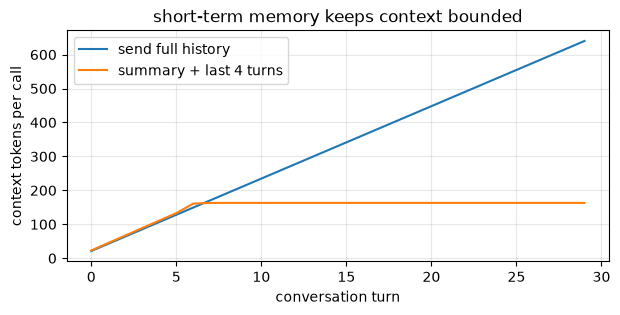

In [7]:
turns = [f"Turn {i}: the project budget is now {1000 + 250 * i} dollars and the deadline moved to week {10 + i}." for i in range(30)]
mem = ConversationMemory(llm=None, max_tokens=150, keep_last=4)    # with llm=None there is no summarizer call; we just keep the most recent text
naive_tokens, mem_tokens = [], []
running = 0
for t in turns:
    mem.add("user", t)
    running += len(t.split()) / 0.75
    naive_tokens.append(running); mem_tokens.append(mem.tokens())
print(f"after {len(turns)} turns: full history ~{naive_tokens[-1]:.0f} tokens | with memory {mem_tokens[-1]} tokens "
      f"({mem.n_summarizations} summarizations)")
print("summary kept (most recent part):", "...", mem.summary[-160:])
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(naive_tokens, label="send full history"); ax.plot(mem_tokens, label="summary + last 4 turns")
ax.set_xlabel("conversation turn"); ax.set_ylabel("context tokens per call"); ax.legend(); ax.grid(alpha=.3); ax.set_title("short-term memory keeps context bounded"); plt.show()

**Long-term:** facts worth keeping across sessions go to a vector store and are recalled by similarity (it is RAG over the agent's own history). Write policy matters as much as retrieval: deduplicate, and decide what is worth remembering.

In [8]:
vm = VectorMemory()
facts = ["The user's name is Ana and she lives in Lima, Peru.",
         "Ana prefers answers in Spanish and short bullet points.",
         "Ana's company sells handmade ceramics online.",
         "Ana's order A100 was delayed in March and she asked for a refund.",
         "Ana uses the API with Python and hits the rate limit at peak hours.",
         "The user's name is Ana and she lives in Lima, Peru."]                    # repeated on purpose to test deduplication
print("stored:", [vm.add(f) for f in facts], "(False = rejected as duplicate)")
MEMORY_EVAL = [("Which city does Ana live in?", 0), ("What does her company sell?", 2), ("Any problems with her orders or refunds?", 3),
               ("How should I format my answers?", 1), ("where does the user live?", 0), ("Does she use Python?", 4)]
hits = 0
for q, gold in MEMORY_EVAL:
    sim, item = vm.search(q, k=1)[0]
    ok = item["text"] == facts[gold]; hits += ok
    print(f"{'OK  ' if ok else 'MISS'} {q:42s} -> ({sim:.2f}) {item['text']}")
print(f"\nrecall@1 of the memory: {hits}/{len(MEMORY_EVAL)}")

stored: [True, True, True, True, True, False] (False = rejected as duplicate)
MISS Which city does Ana live in?               -> (0.20) Ana prefers answers in Spanish and short bullet points.
OK   What does her company sell?                -> (0.30) Ana's company sells handmade ceramics online.
MISS Any problems with her orders or refunds?   -> (0.18) Ana uses the API with Python and hits the rate limit at peak hours.
OK   How should I format my answers?            -> (0.26) Ana prefers answers in Spanish and short bullet points.
OK   where does the user live?                  -> (0.37) The user's name is Ana and she lives in Lima, Peru.
OK   Does she use Python?                       -> (0.19) Ana uses the API with Python and hits the rate limit at peak hours.

recall@1 of the memory: 4/6


Look at the misses: the offline embedder is **lexical** (hashed TF-IDF). It matches surface words — a query mentioning "Ana" is pulled towards any fact containing "Ana" — and it does not know that *city* relates to *lives in Lima*, and it treats *orders*/*refunds* and *order*/*refund* as different words (no stemming). That is exactly why production memory uses neural embeddings (`SentenceTransformerEmbedder` in `llm_edu_suite.rag`) and why you should **measure recall@k on a set of queries** before trusting a memory system, as we just did.

## 5. Multi-agent: a supervisor routing to specialists

Instead of one agent with every tool, a **supervisor** sends each request to a specialist with a small prompt and a few tools — tool-selection accuracy goes up, at the cost of one routing hop. Routing *is* classification, so we evaluate it like a classifier.

In [9]:
workers = [
    Worker("billing", "orders, invoices, payments, refunds, order status, totals and taxes", lambda q: BudgetedAgent(MockLLM(), registry).run(q).answer),
    Worker("support", "shipping times, account security, passwords, support hours, the public API", lambda q: search_docs(q)),
    Worker("analytics", "arithmetic, calculations, percentages, numbers, averages", lambda q: BudgetedAgent(MockLLM(), registry).run(q).answer),
]
ROUTING_EVAL = [("Where is my order B200?", "billing"), ("I want a refund for my invoice", "billing"),
                ("What taxes were applied to my payment?", "billing"), ("How long does express shipping take?", "support"),
                ("How do I enable two-factor security on my account?", "support"), ("What are your support hours?", "support"),
                ("What is the API rate limit?", "support"), ("Calculate 15 percent of 240", "analytics"),
                ("What is the average of 10, 20 and 30?", "analytics"), ("Compute 2 to the power of 10", "analytics"),
                ("My password reset email never arrived", "support"), ("Was I charged twice for order A100?", "billing")]
for strategy in ("embedding", "llm"):
    sup = Supervisor(workers, llm=MockLLM(), strategy=strategy)
    preds = [sup.route(q) for q, _ in ROUTING_EVAL]
    acc = np.mean([p == g for p, (_, g) in zip(preds, ROUTING_EVAL)])
    errors = [(q, g, p) for p, (q, g) in zip(preds, ROUTING_EVAL) if p != g]
    print(f"routing strategy {strategy:9s}: accuracy {acc:.0%}  errors: {errors}")
sup = Supervisor(workers, strategy="embedding")
print("\nexample:", sup.run("How long does express shipping take?"))

routing strategy embedding: accuracy 67%  errors: [('Calculate 15 percent of 240', 'analytics', 'billing'), ('What is the average of 10, 20 and 30?', 'analytics', 'billing'), ('Compute 2 to the power of 10', 'analytics', 'support'), ('My password reset email never arrived', 'support', 'billing')]
routing strategy llm      : accuracy 42%  errors: [('How long does express shipping take?', 'support', 'billing'), ('How do I enable two-factor security on my account?', 'support', 'billing'), ('What is the API rate limit?', 'support', 'billing'), ('Calculate 15 percent of 240', 'analytics', 'billing'), ('What is the average of 10, 20 and 30?', 'analytics', 'billing'), ('Compute 2 to the power of 10', 'analytics', 'billing'), ('My password reset email never arrived', 'support', 'billing')]

example: {'worker': 'support', 'answer': '# Shipping Standard shipping takes 3 to 7 business days and is free for orders over 50 dollars. Express shipping delivers in 1 to 2 business days and costs 15 dolla

Two cheap routers, two different error profiles — and neither is perfect. In production you would (a) measure on a few hundred real requests, (b) add a fallback ("not sure → general agent" or ask the user), and (c) log every routing decision so misroutes can be reviewed.

## Takeaways

- **Start simple, measure, then add autonomy.** Single call → fixed workflow → router → agent → multi-agent, in that order.
- **Every agent needs budgets and a stop reason**, and every write action needs a confirmation gate.
- **Planning, reflection and routing are only as good as their evaluation:** keep an eval set of tasks with expected trajectories and facts; track success, tool precision/recall, steps and cost per task.
- **Memory is retrieval:** measure recall, deduplicate, keep the context bounded.
- Production frameworks implementing these patterns: LangGraph (graphs with state + checkpoints), OpenAI Agents SDK / Claude Agent SDK (tools, handoffs, guardrails), CrewAI, AutoGen. Notebook 15 adds **observability** and notebook 16 the **Model Context Protocol** for connecting tools.

**Next:** `15_observability_llmops.ipynb`.